In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
import warnings

warnings.filterwarnings('ignore')

# Publication-quality aesthetics
sns.set_theme(style="ticks", context="talk")
plt.rcParams.update({
    'figure.figsize': (16, 7),
    'axes.titlesize': 18,
    'axes.titleweight': 'bold',
    'axes.labelsize': 14,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'lines.linewidth': 1.5,
    'grid.alpha': 0.5,
    'grid.linestyle': '--'
})

print("Veteran ML Environment Initialized.")

Veteran ML Environment Initialized.


In [25]:
file_path = 'adani.csv'

try:
    df = pd.read_csv(file_path)

    # Rename for standard convention
    df.rename(columns={
        'Start time UTC': 'timestamp',
        'Electricity consumption (MWh)': 'consumption'
    }, inplace=True)

    # Convert to datetime and set as index
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df.set_index('timestamp', inplace=True)

    # Drop redundant column
    if 'End time UTC' in df.columns:
        df.drop(columns=['End time UTC'], inplace=True)

    # Sort chronologically (Absolute rule in Time Series)
    df.sort_index(inplace=True)

    print(f"Data loaded. Shape: {df.shape}")
    print(f"Time Range: {df.index.min()} to {df.index.max()}")
except Exception as e:
    print(f"Error loading data: {e}")

Data loaded. Shape: (52966, 1)
Time Range: 2015-12-31 21:00:00 to 2021-12-31 20:00:00


In [26]:
# Generate the expected perfect hourly timeline
expected_index = pd.date_range(start=df.index.min(), end=df.index.max(), freq='H')

# Find missing timestamps
missing_timestamps = expected_index.difference(df.index)
print(f"Expected rows: {len(expected_index)}")
print(f"Actual rows: {len(df)}")
print(f"Missing hourly timestamps: {len(missing_timestamps)}")

# Reindex to expose the missing rows as NaNs
df = df.reindex(expected_index)

# Analyze gap sizes
gap_mask = df['consumption'].isna()
gap_sizes = gap_mask.groupby((~gap_mask).cumsum()).sum()
gap_sizes = gap_sizes[gap_sizes > 0]

if not gap_sizes.empty:
    print("\nGap Size Distribution (How many consecutive hours are missing?):")
    print(gap_sizes.value_counts().sort_index())
else:
    print("\nNo missing gaps found!")

Expected rows: 52608
Actual rows: 52966
Missing hourly timestamps: 378

Gap Size Distribution (How many consecutive hours are missing?):
consumption
1     125
2      41
3      12
4       4
5       6
6       2
9       2
12      1
14      1
33      1
Name: count, dtype: int64


In [27]:
missing_initial = df['consumption'].isna().sum()

# Step 1: Time-based interpolation for short gaps (limit=3 hours)
df['consumption'] = df['consumption'].interpolate(method='time', limit=3)

# Step 2: Seasonal fallback for longer gaps (shift by 24 hours)
# We loop to ensure gaps larger than 24h are eventually filled by previous valid days
while df['consumption'].isna().sum() > 0:
    df['consumption'] = df['consumption'].fillna(df['consumption'].shift(24))

missing_final = df['consumption'].isna().sum()
print(f"Imputation Complete. Missing values reduced from {missing_initial} to {missing_final}.")

Imputation Complete. Missing values reduced from 378 to 0.


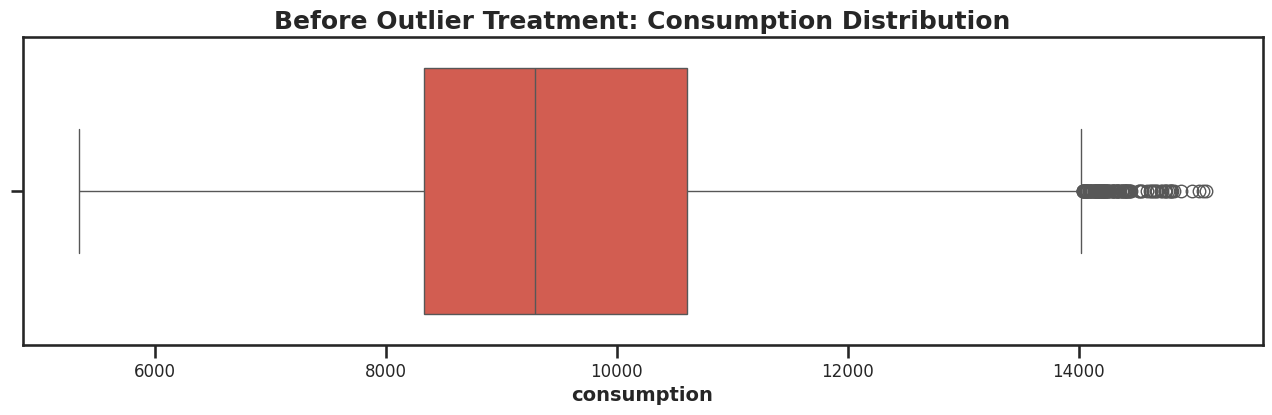

Outliers capped below 6619.00 and above 13417.00


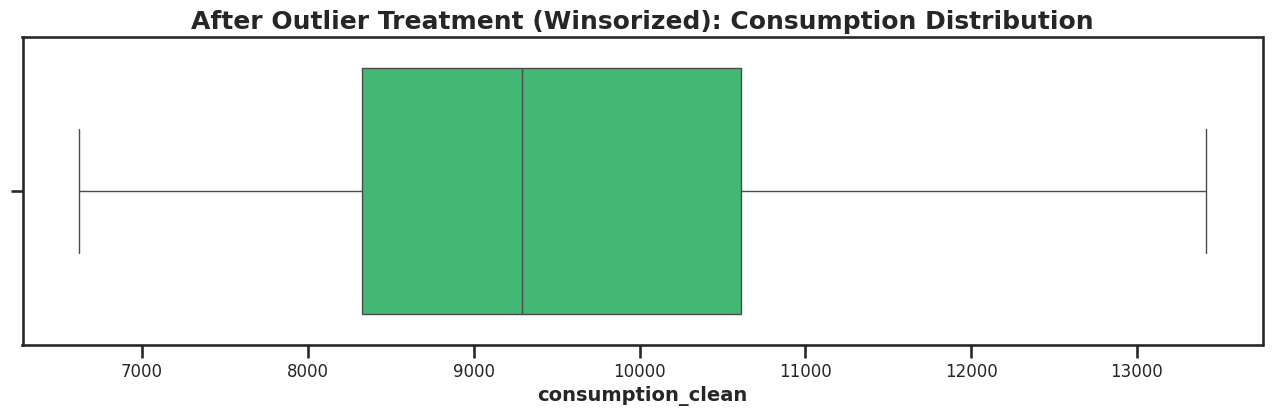

In [28]:
plt.figure(figsize=(16, 4))
sns.boxplot(x=df['consumption'], color='#e74c3c')
plt.title('Before Outlier Treatment: Consumption Distribution')
plt.show()

# Calculate 1st and 99th percentiles
lower_bound = df['consumption'].quantile(0.01)
upper_bound = df['consumption'].quantile(0.99)

# Cap the outliers (Winsorization)
df['consumption_clean'] = np.clip(df['consumption'], lower_bound, upper_bound)

print(f"Outliers capped below {lower_bound:.2f} and above {upper_bound:.2f}")

plt.figure(figsize=(16, 4))
sns.boxplot(x=df['consumption_clean'], color='#2ecc71')
plt.title('After Outlier Treatment (Winsorized): Consumption Distribution')
plt.show()

In [29]:
df_feat = df[['consumption_clean']].copy()
df_feat.rename(columns={'consumption_clean': 'target'}, inplace=True)

# 1. Standard Time Features
df_feat['hour'] = df_feat.index.hour
df_feat['dayofweek'] = df_feat.index.dayofweek
df_feat['month'] = df_feat.index.month
df_feat['is_weekend'] = np.where(df_feat.index.dayofweek >= 5, 1, 0)

# 2. Cyclical Encoding (Crucial for ML models)
df_feat['hour_sin'] = np.sin(2 * np.pi * df_feat['hour'] / 24)
df_feat['hour_cos'] = np.cos(2 * np.pi * df_feat['hour'] / 24)
df_feat['month_sin'] = np.sin(2 * np.pi * df_feat['month'] / 12)
df_feat['month_cos'] = np.cos(2 * np.pi * df_feat['month'] / 12)

# 3. Lag Features (What was the consumption 1 hour ago? 24 hours ago?)
df_feat['lag_1'] = df_feat['target'].shift(1)
df_feat['lag_24'] = df_feat['target'].shift(24)
df_feat['lag_168'] = df_feat['target'].shift(168) # 1 week ago

# 4. Rolling Statistics (Momentum)
df_feat['rolling_mean_24'] = df_feat['target'].shift(1).rolling(window=24).mean()
df_feat['rolling_std_24'] = df_feat['target'].shift(1).rolling(window=24).std()

# Drop NaNs created by lags/rolling
df_feat.dropna(inplace=True)

display(df_feat.head())

,target,hour,dayofweek,month,is_weekend,hour_sin,hour_cos,month_sin,month_cos,lag_1,lag_24,lag_168,rolling_mean_24,rolling_std_24
2016-01-07 21:00:00,13417.0,21,3,1,0,-0.707107,0.707107,0.5,0.866025,13417.0,13417.0,10800.0,13324.833333,198.301410
2016-01-07 22:00:00,13417.0,22,3,1,0,-0.500000,0.866025,0.5,0.866025,13417.0,13285.0,10431.0,13324.833333,198.301410
2016-01-07 23:00:00,13369.0,23,3,1,0,-0.258819,0.965926,0.5,0.866025,13417.0,13011.0,10005.0,13330.333333,198.977968
2016-01-08 00:00:00,13142.0,0,4,1,0,0.000000,1.000000,0.5,0.866025,13369.0,12821.0,9722.0,13345.250000,187.059918
2016-01-08 01:00:00,13111.0,1,4,1,0,0.258819,0.965926,0.5,0.866025,13142.0,12821.0,9599.0,13358.625000,157.007564


In [30]:
print("Running Augmented Dickey-Fuller Test...")
adf_result = adfuller(df_feat['target'])

print(f'ADF Statistic: {adf_result[0]:.4f}')
print(f'p-value: {adf_result[1]:.4f}')
print('Critical Values:')
for key, value in adf_result[4].items():
    print(f'   {key}: {value:.4f}')

if adf_result[1] <= 0.05:
    print("\nConclusion: Strong evidence against the null hypothesis. The time series is STRICTLY STATIONARY.")
else:
    print("\nConclusion: Weak evidence against null hypothesis. The time series is NON-STATIONARY (Trend exists).")

Running Augmented Dickey-Fuller Test...
ADF Statistic: -6.1118
p-value: 0.0000
Critical Values:
   1%: -3.4305
   5%: -2.8616
   10%: -2.5668

Conclusion: Strong evidence against the null hypothesis. The time series is STRICTLY STATIONARY.


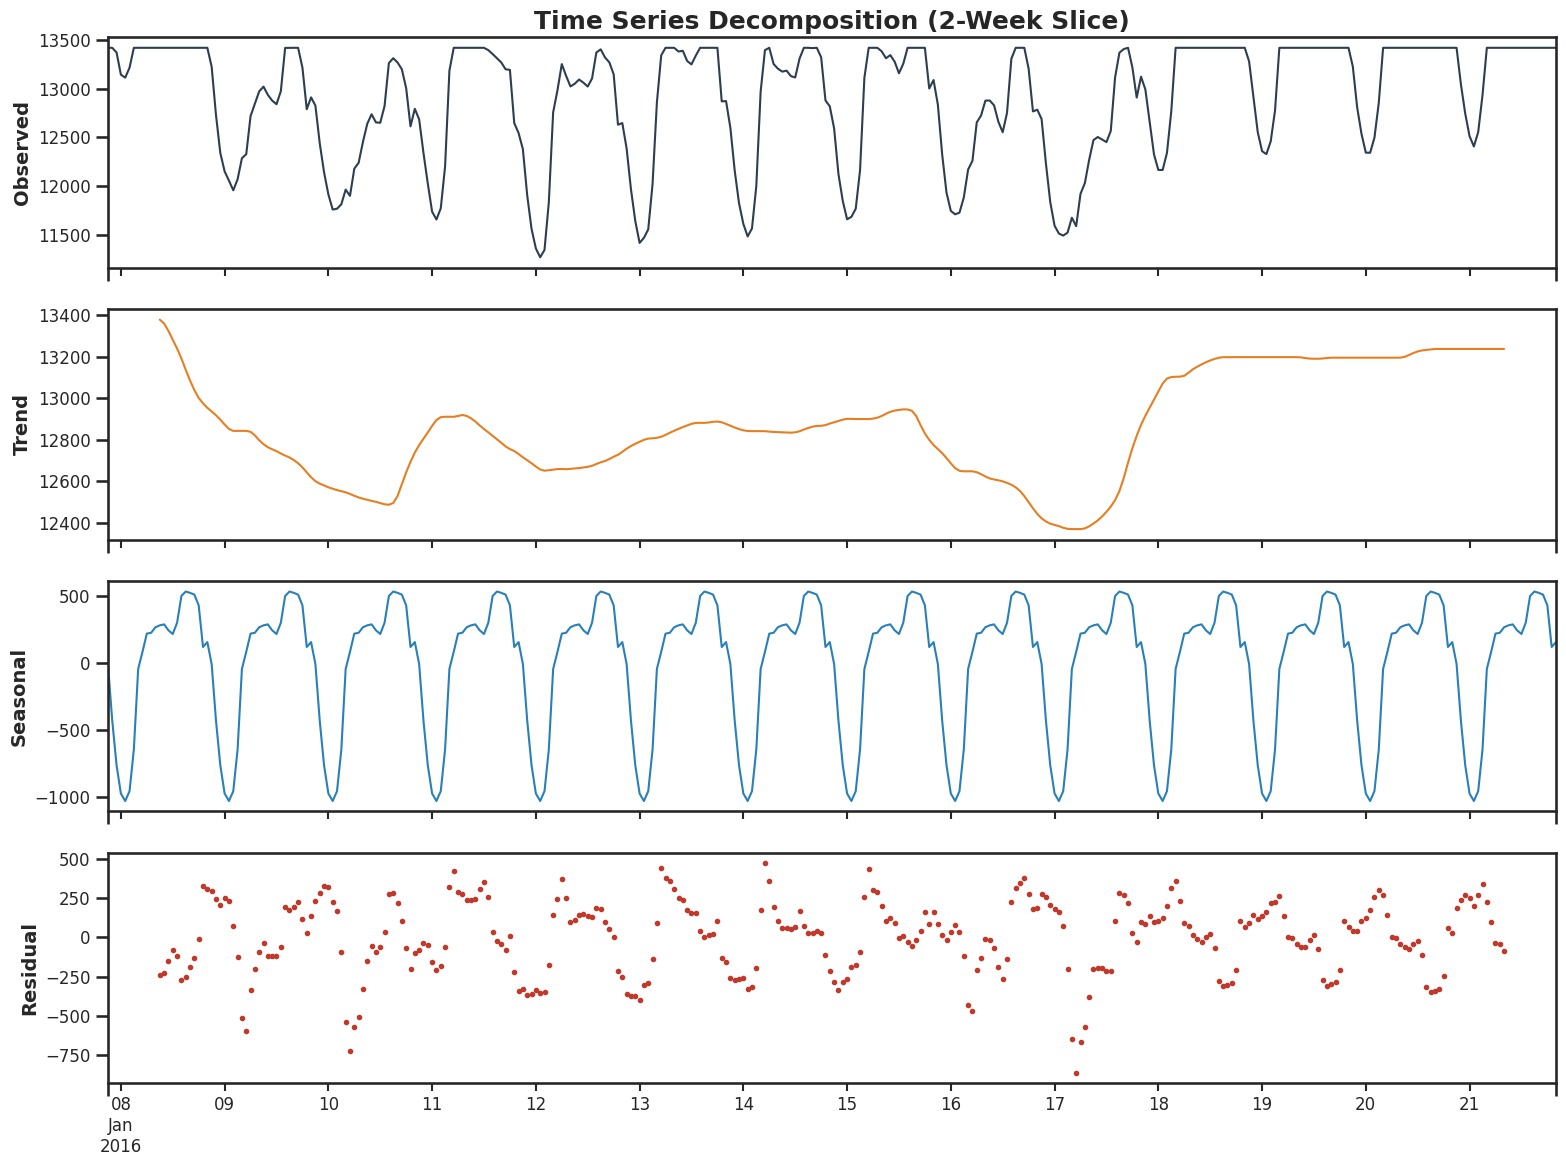

In [31]:
# Slice 2 weeks of data (14 days * 24 hours = 336 hours)
subset = df_feat['target'].iloc[:336]

decomposition = seasonal_decompose(subset, model='additive', period=24)

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
decomposition.observed.plot(ax=axes[0], color='#2c3e50')
axes[0].set_ylabel('Observed')
axes[0].set_title('Time Series Decomposition (2-Week Slice)', fontweight='bold')

decomposition.trend.plot(ax=axes[1], color='#e67e22')
axes[1].set_ylabel('Trend')

decomposition.seasonal.plot(ax=axes[2], color='#2980b9')
axes[2].set_ylabel('Seasonal')

decomposition.resid.plot(ax=axes[3], color='#c0392b', style='o', markersize=3)
axes[3].set_ylabel('Residual')

plt.tight_layout()
plt.show()

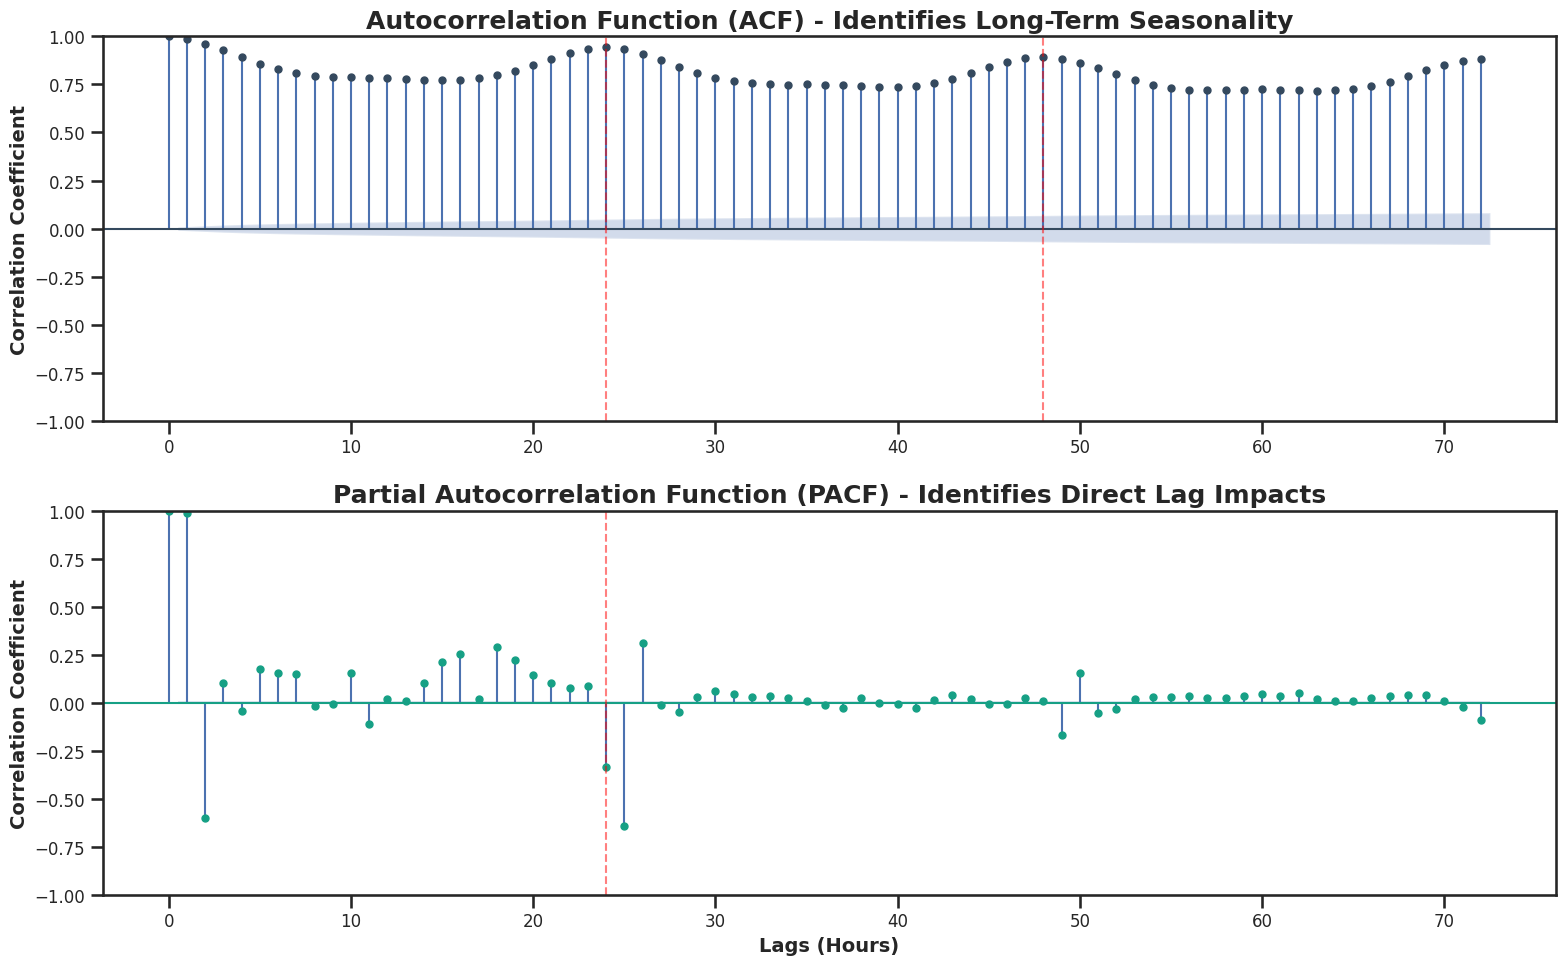

In [32]:
fig, ax = plt.subplots(2, 1, figsize=(16, 10))

# ACF up to 3 days (72 hours)
plot_acf(df_feat['target'], lags=72, ax=ax[0], color='#34495e', alpha=0.05)
ax[0].set_title('Autocorrelation Function (ACF) - Identifies Long-Term Seasonality', fontweight='bold')
ax[0].set_ylabel('Correlation Coefficient')
ax[0].axvline(24, color='red', linestyle='--', alpha=0.5) # Mark 24h
ax[0].axvline(48, color='red', linestyle='--', alpha=0.5) # Mark 48h

# PACF up to 3 days (72 hours)
plot_pacf(df_feat['target'], lags=72, ax=ax[1], color='#16a085', method='ywm', alpha=0.05)
ax[1].set_title('Partial Autocorrelation Function (PACF) - Identifies Direct Lag Impacts', fontweight='bold')
ax[1].set_ylabel('Correlation Coefficient')
ax[1].set_xlabel('Lags (Hours)')
ax[1].axvline(24, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

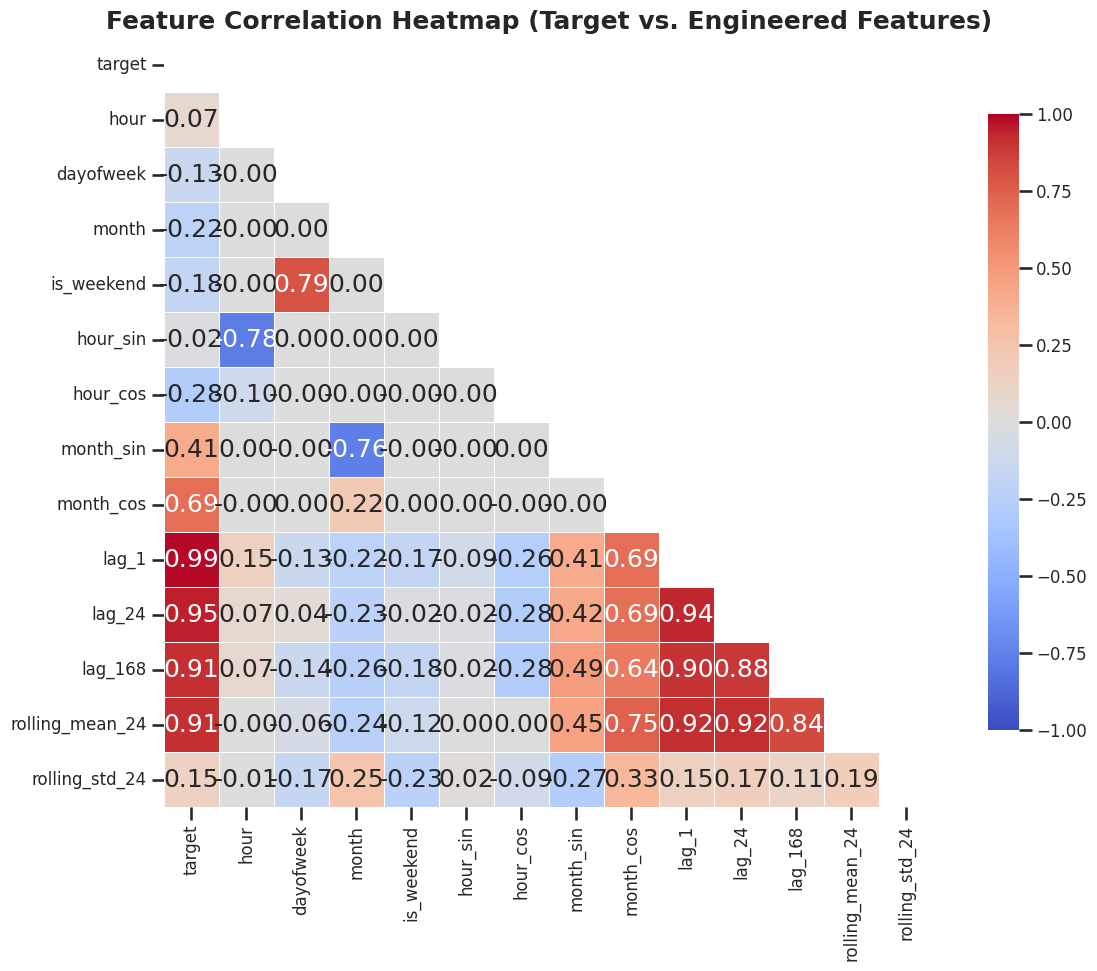

Top Features Correlated with Target:
lag_1              0.987687
lag_24             0.946140
rolling_mean_24    0.912666
lag_168            0.910323
month_cos          0.692630
Name: target, dtype: float64


In [33]:
plt.figure(figsize=(14, 10))

# Calculate correlation matrix
corr_matrix = df_feat.corr()

# Create a mask for the upper triangle to make it look clean
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot heatmap
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=.5, cbar_kws={"shrink": .8})

plt.title('Feature Correlation Heatmap (Target vs. Engineered Features)', fontsize=18, fontweight='bold')
plt.show()

# Print top correlations with target
print("Top Features Correlated with Target:")
print(corr_matrix['target'].sort_values(ascending=False)[1:6])

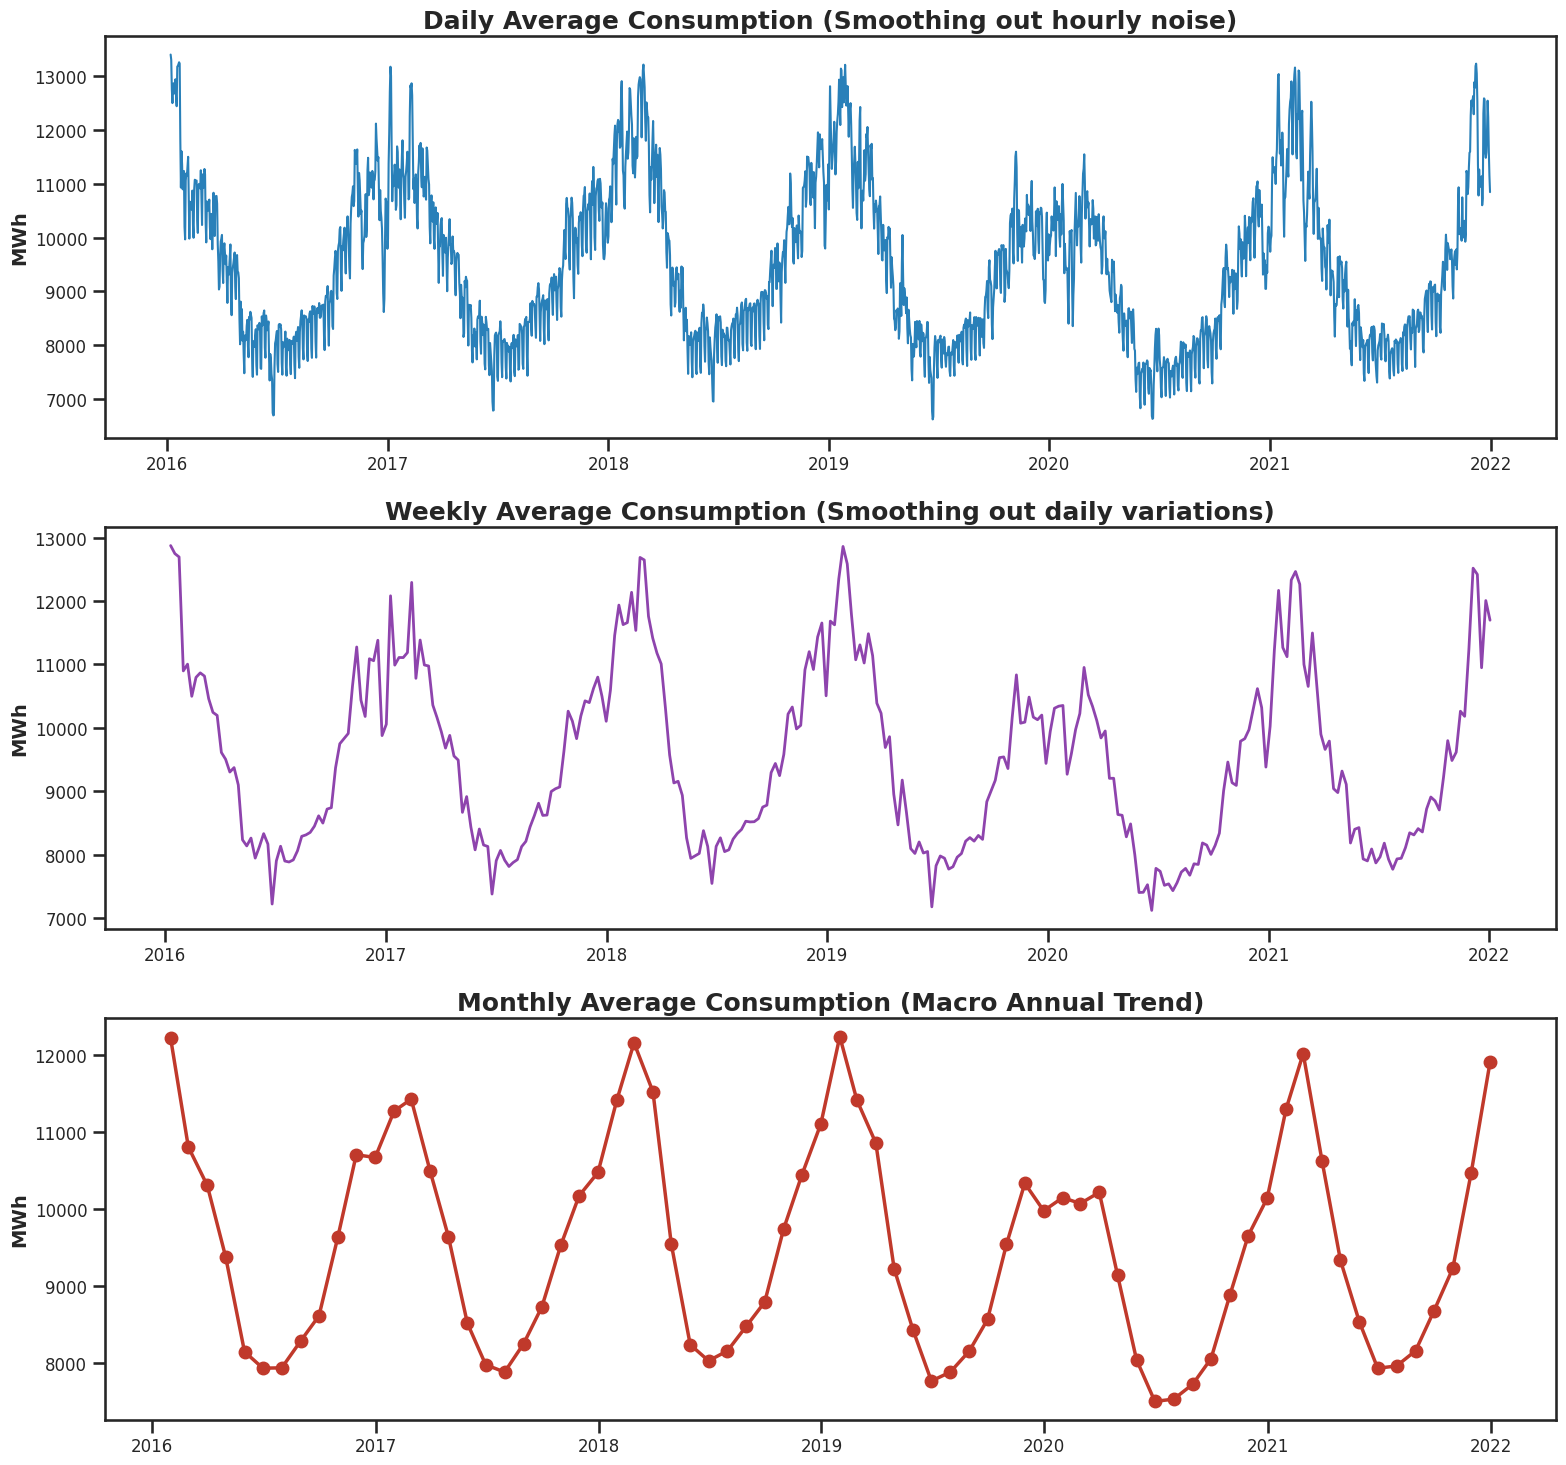

In [34]:
fig, axes = plt.subplots(3, 1, figsize=(16, 15), sharex=False)

# Daily Average
daily_data = df_feat['target'].resample('D').mean()
axes[0].plot(daily_data.index, daily_data, color='#2980b9', linewidth=1.5)
axes[0].set_title('Daily Average Consumption (Smoothing out hourly noise)', fontweight='bold')
axes[0].set_ylabel('MWh')

# Weekly Average
weekly_data = df_feat['target'].resample('W').mean()
axes[1].plot(weekly_data.index, weekly_data, color='#8e44ad', linewidth=2)
axes[1].set_title('Weekly Average Consumption (Smoothing out daily variations)', fontweight='bold')
axes[1].set_ylabel('MWh')

# Monthly Average
monthly_data = df_feat['target'].resample('M').mean()
axes[2].plot(monthly_data.index, monthly_data, color='#c0392b', linewidth=2.5, marker='o')
axes[2].set_title('Monthly Average Consumption (Macro Annual Trend)', fontweight='bold')
axes[2].set_ylabel('MWh')

plt.tight_layout()
plt.show()

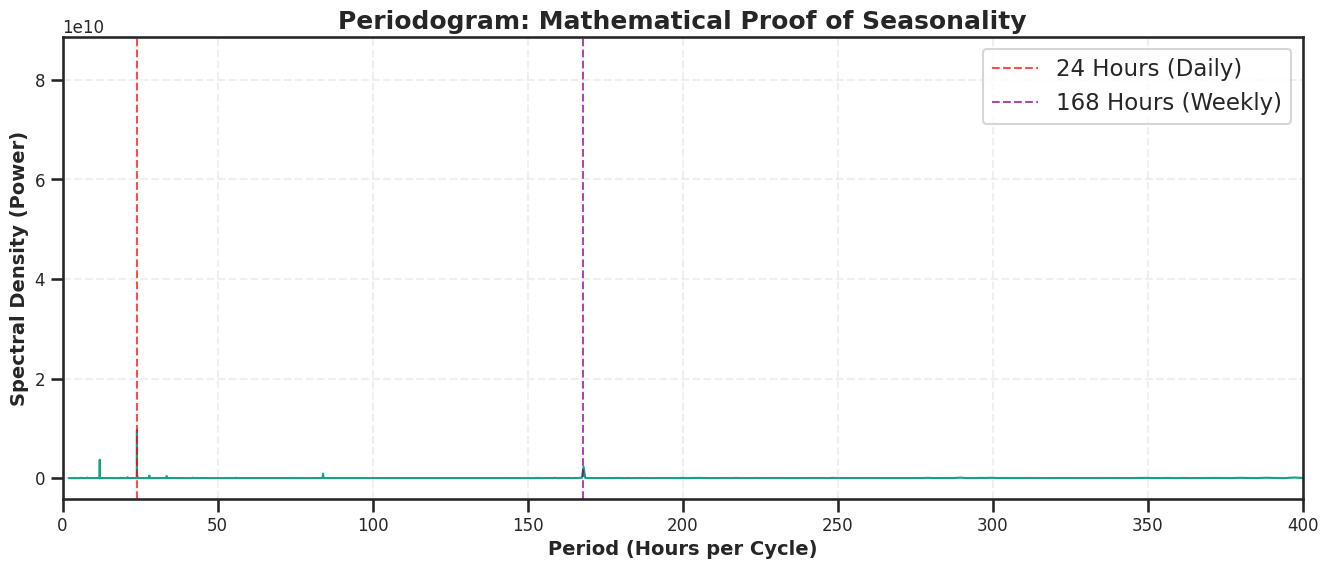

Insight: The massive spikes at 24 and 168 mathematically prove that daily and weekly lags are the most critical features for your model.


In [35]:
from scipy import signal

# Calculate the periodogram
frequencies, spectrum = signal.periodogram(df_feat['target'].dropna(), fs=1) # fs=1 means 1 sample per hour

# Convert frequencies to periods (hours per cycle)
# Ignore the 0 frequency (infinite period)
periods = 1 / frequencies[1:]
spectrum = spectrum[1:]

plt.figure(figsize=(16, 6))
plt.plot(periods, spectrum, color='#16a085')
plt.title('Periodogram: Mathematical Proof of Seasonality', fontsize=18, fontweight='bold')
plt.xlabel('Period (Hours per Cycle)')
plt.ylabel('Spectral Density (Power)')

# Limit x-axis to focus on meaningful periods (up to 1 month / 720 hours)
plt.xlim(0, 400)

# Highlight known seasonalities
plt.axvline(24, color='red', linestyle='--', alpha=0.7, label='24 Hours (Daily)')
plt.axvline(168, color='purple', linestyle='--', alpha=0.7, label='168 Hours (Weekly)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Insight: The massive spikes at 24 and 168 mathematically prove that daily and weekly lags are the most critical features for your model.")

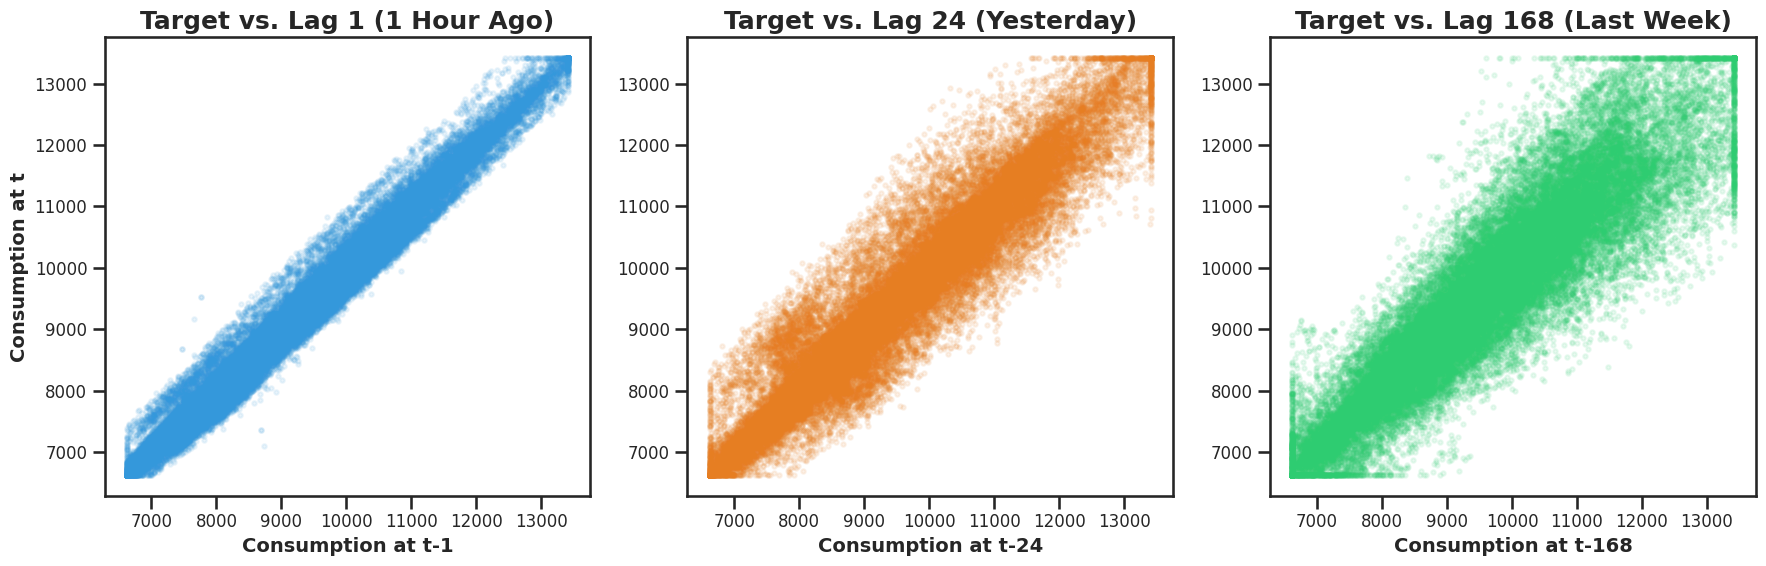

Insight: The tighter the cluster forms a diagonal line, the stronger the predictive power of that lag.


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Lag 1 (1 Hour Ago)
axes[0].scatter(df_feat['lag_1'], df_feat['target'], alpha=0.1, color='#3498db', s=10)
axes[0].set_title('Target vs. Lag 1 (1 Hour Ago)', fontweight='bold')
axes[0].set_xlabel('Consumption at t-1')
axes[0].set_ylabel('Consumption at t')

# Lag 24 (Exactly 1 Day Ago)
axes[1].scatter(df_feat['lag_24'], df_feat['target'], alpha=0.1, color='#e67e22', s=10)
axes[1].set_title('Target vs. Lag 24 (Yesterday)', fontweight='bold')
axes[1].set_xlabel('Consumption at t-24')

# Lag 168 (Exactly 1 Week Ago)
axes[2].scatter(df_feat['lag_168'], df_feat['target'], alpha=0.1, color='#2ecc71', s=10)
axes[2].set_title('Target vs. Lag 168 (Last Week)', fontweight='bold')
axes[2].set_xlabel('Consumption at t-168')

plt.tight_layout()
plt.show()

print("Insight: The tighter the cluster forms a diagonal line, the stronger the predictive power of that lag.")

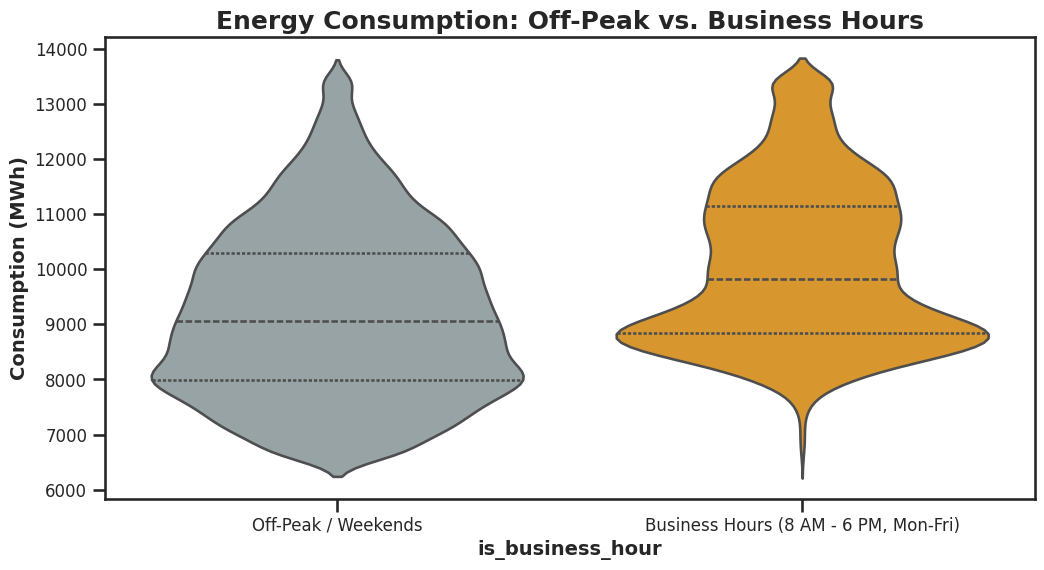

In [37]:
# Define Business Hours (e.g., 8 AM to 6 PM, Monday to Friday)
df_feat['is_business_hour'] = np.where(
    (df_feat['hour'] >= 8) & (df_feat['hour'] <= 18) & (df_feat['is_weekend'] == 0),
    1, 0
)

plt.figure(figsize=(12, 6))
sns.violinplot(
    x='is_business_hour',
    y='target',
    data=df_feat,
    palette=['#95a5a6', '#f39c12'],
    inner='quartile'
)

plt.title('Energy Consumption: Off-Peak vs. Business Hours', fontsize=18, fontweight='bold')
plt.xticks(ticks=[0, 1], labels=['Off-Peak / Weekends', 'Business Hours (8 AM - 6 PM, Mon-Fri)'])
plt.ylabel('Consumption (MWh)')
plt.show()

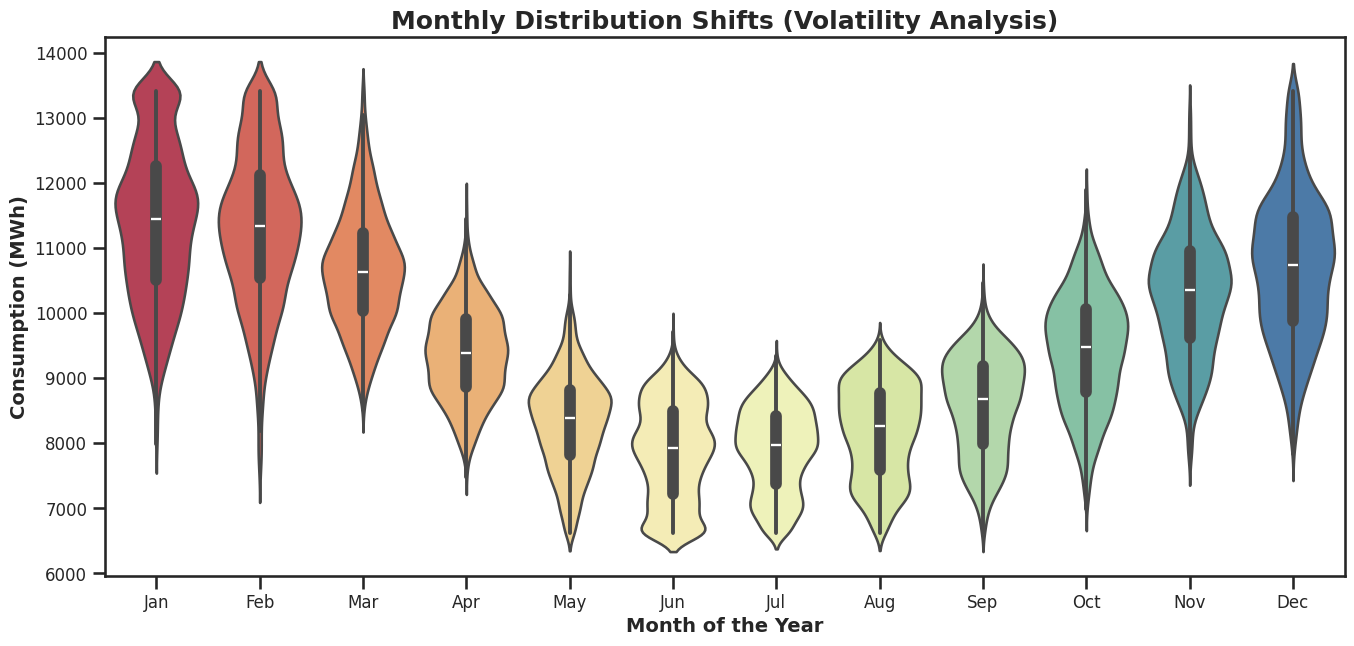

Insight: Look at the 'fatness' of the violins. Fatter sections mean the grid spends more time at that megawatt level. Longer tails mean higher volatility/spikes in that specific month.


In [38]:
plt.figure(figsize=(16, 7))

sns.violinplot(
    x='month',
    y='target',
    data=df_feat,
    palette='Spectral',
    inner='box'
)

plt.title('Monthly Distribution Shifts (Volatility Analysis)', fontsize=18, fontweight='bold')
plt.xlabel('Month of the Year')
plt.ylabel('Consumption (MWh)')

# Map month numbers to names for better readability
month_names =['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.xticks(ticks=range(0, 12), labels=month_names)

plt.show()

print("Insight: Look at the 'fatness' of the violins. Fatter sections mean the grid spends more time at that megawatt level. Longer tails mean higher volatility/spikes in that specific month.")

In [40]:
# Drop any remaining NaNs caused by the 168-hour lag
final_df = df_feat.dropna().copy()

# Separate Features (X) and Target (y)
# We drop the target and the raw 'hour'/'month' since we have cyclical encoded them
features_to_drop = ['target', 'hour', 'month']
X = final_df.drop(columns=features_to_drop)
y = final_df['target']

print("--- Final Feature Matrix Ready for Modeling ---")
print(f"Total Samples: {X.shape[0]}")
print(f"Total Features: {X.shape[1]}")
print("\nFeatures included:")
for col in X.columns:
    print(f" - {col}")

# Save the ultimate dataset
final_df.to_csv('adani_ultimate_features.csv')
print("\nDataset saved as 'adani_ultimate_features.csv'.")

--- Final Feature Matrix Ready for Modeling ---
Total Samples: 52440
Total Features: 12

Features included:
 - dayofweek
 - is_weekend
 - hour_sin
 - hour_cos
 - month_sin
 - month_cos
 - lag_1
 - lag_24
 - lag_168
 - rolling_mean_24
 - rolling_std_24
 - is_business_hour

Dataset saved as 'adani_ultimate_features.csv'.


In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# 80-20 Chronological Split
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training samples: {X_train.shape[0]} (80%)")
print(f"Testing samples: {X_test.shape[0]} (20%)")

def evaluate_model(y_true, y_pred, model_name):
    """Calculates and prints core forecasting metrics."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    r2 = r2_score(y_true, y_pred)

    print(f"--- {model_name} Performance ---")
    print(f"MAE:  {mae:.2f} MWh (Average error in Megawatts)")
    print(f"RMSE: {rmse:.2f} MWh (Penalizes larger errors)")
    print(f"MAPE: {mape:.2f}% (Percentage error - Crucial for Hackathons)")
    print(f"R2:   {r2:.4f} (Variance explained)\n")
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "R2": r2}

Training samples: 41952 (80%)
Testing samples: 10488 (20%)


In [42]:
import xgboost as xgb
import lightgbm as lgb
import time

# 1. XGBoost Regressor
print("Training XGBoost...")
start_time = time.time()
xgb_model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=200, learning_rate=0.05, random_state=42)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)
xgb_time = time.time() - start_time
xgb_metrics = evaluate_model(y_test, xgb_preds, f"XGBoost (Time: {xgb_time:.2f}s)")

# 2. LightGBM Regressor
print("Training LightGBM...")
start_time = time.time()
lgb_model = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, random_state=42, force_col_wise=True)
lgb_model.fit(X_train, y_train)
lgb_preds = lgb_model.predict(X_test)
lgb_time = time.time() - start_time
lgb_metrics = evaluate_model(y_test, lgb_preds, f"LightGBM (Time: {lgb_time:.2f}s)")

print("Insight: LightGBM usually trains much faster and yields slightly better or equal MAPE on tabular time-series data.")

Training XGBoost...
--- XGBoost (Time: 1.17s) Performance ---
MAE:  79.51 MWh (Average error in Megawatts)
RMSE: 111.24 MWh (Penalizes larger errors)
MAPE: 0.83% (Percentage error - Crucial for Hackathons)
R2:   0.9950 (Variance explained)

Training LightGBM...
[LightGBM] [Info] Total Bins 1348
[LightGBM] [Info] Number of data points in the train set: 41952, number of used features: 12
[LightGBM] [Info] Start training from score 9437.833143
--- LightGBM (Time: 3.12s) Performance ---
MAE:  77.79 MWh (Average error in Megawatts)
RMSE: 109.24 MWh (Penalizes larger errors)
MAPE: 0.81% (Percentage error - Crucial for Hackathons)
R2:   0.9951 (Variance explained)

Insight: LightGBM usually trains much faster and yields slightly better or equal MAPE on tabular time-series data.


In [43]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

# TimeSeriesSplit prevents data leakage during cross-validation
tscv = TimeSeriesSplit(n_splits=3)

# Parameter grid for LightGBM (Chosen based on STLF research papers)
param_grid = {
    'n_estimators':[200, 500, 1000],
    'learning_rate':[0.01, 0.05, 0.1],
    'max_depth': [5, 7, 10, -1],
    'num_leaves': [31, 63, 127],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

print("Starting Hyperparameter Tuning for LightGBM...")
lgb_base = lgb.LGBMRegressor(random_state=42, force_col_wise=True)

# Note: n_iter is set to 10 for speed. For your final hackathon submission, change n_iter to 50!
random_search = RandomizedSearchCV(
    estimator=lgb_base,
    param_distributions=param_grid,
    n_iter=10,
    scoring='neg_mean_absolute_percentage_error',
    cv=tscv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print(f"\nBest Parameters Found: {random_search.best_params_}")
best_model = random_search.best_estimator_

# Evaluate the tuned model
tuned_preds = best_model.predict(X_test)
tuned_metrics = evaluate_model(y_test, tuned_preds, "Tuned LightGBM (Final Model)")

Starting Hyperparameter Tuning for LightGBM...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
[LightGBM] [Info] Total Bins 1348
[LightGBM] [Info] Number of data points in the train set: 41952, number of used features: 12
[LightGBM] [Info] Start training from score 9437.833143

Best Parameters Found: {'subsample': 0.8, 'num_leaves': 31, 'n_estimators': 1000, 'max_depth': -1, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
--- Tuned LightGBM (Final Model) Performance ---
MAE:  69.37 MWh (Average error in Megawatts)
RMSE: 102.79 MWh (Penalizes larger errors)
MAPE: 0.72% (Percentage error - Crucial for Hackathons)
R2:   0.9957 (Variance explained)



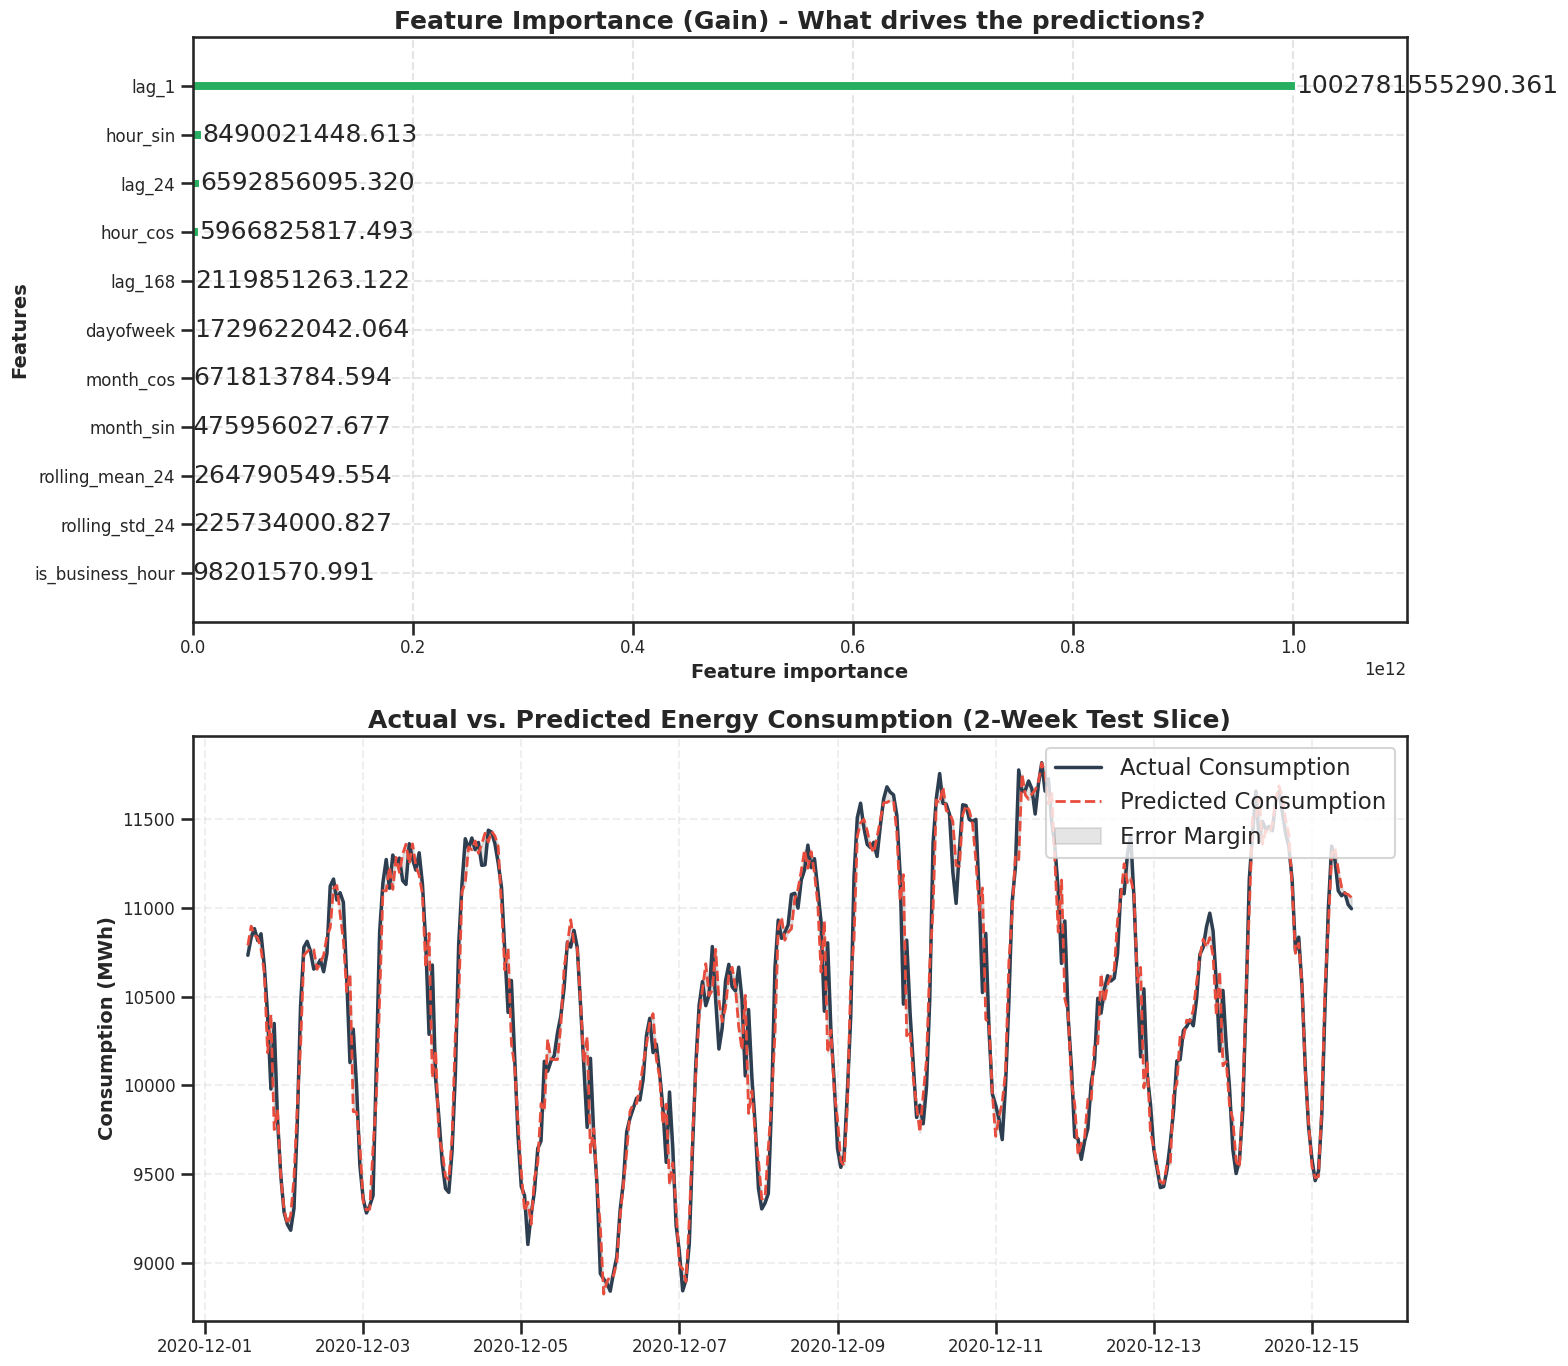

Hackathon Tip: Show the Feature Importance plot to the judges. It proves your model isn't guessing, but is heavily relying on the lag_1, lag_24, and rolling_mean features you engineered.


In [44]:
fig, axes = plt.subplots(2, 1, figsize=(16, 14))

# 1. Feature Importance (Gain)
# Gain shows which features contributed the most to reducing the error
lgb.plot_importance(best_model, ax=axes[0], importance_type='gain', max_num_features=12, color='#27ae60')
axes[0].set_title('Feature Importance (Gain) - What drives the predictions?', fontsize=18, fontweight='bold')
axes[0].set_ylabel('Features')

# 2. Actual vs Predicted (Zoomed in on a 2-week slice of the test set)
# Slicing 336 hours (14 days) for clear visualization
slice_start = 1000
slice_end = 1336

axes[1].plot(y_test.index[slice_start:slice_end], y_test.iloc[slice_start:slice_end], label='Actual Consumption', color='#2c3e50', linewidth=2.5)
axes[1].plot(y_test.index[slice_start:slice_end], tuned_preds[slice_start:slice_end], label='Predicted Consumption', color='#e74c3c', linestyle='--', linewidth=2)

# Highlight the area between the curves to show the error margin
axes[1].fill_between(y_test.index[slice_start:slice_end],
                     y_test.iloc[slice_start:slice_end],
                     tuned_preds[slice_start:slice_end],
                     color='gray', alpha=0.2, label='Error Margin')

axes[1].set_title('Actual vs. Predicted Energy Consumption (2-Week Test Slice)', fontsize=18, fontweight='bold')
axes[1].set_ylabel('Consumption (MWh)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Hackathon Tip: Show the Feature Importance plot to the judges. It proves your model isn't guessing, but is heavily relying on the lag_1, lag_24, and rolling_mean features you engineered.")

In [45]:
from sklearn.metrics import mean_absolute_percentage_error
import lightgbm as lgb
import numpy as np

print("Initializing Walk-Forward Validation (24-Hour Forecast Horizon)...")

# We will test on the last 14 days (336 hours) to simulate a 2-week production run
forecast_horizon = 24
test_size = 336
start_idx = len(X) - test_size

wf_predictions = []
wf_actuals =[]

# Base model for Walk-Forward
wf_model = lgb.LGBMRegressor(random_state=42, force_col_wise=True, n_estimators=200)

# Walk-forward loop: Train -> Predict 24h -> Move window forward by 24h
for i in range(start_idx, len(X), forecast_horizon):
    # Expanding window: Train from beginning up to current step
    X_train_wf = X.iloc[:i]
    y_train_wf = y.iloc[:i]

    # Test on the next 24 hours
    X_test_wf = X.iloc[i:i+forecast_horizon]
    y_test_wf = y.iloc[i:i+forecast_horizon]

    # Fit and predict
    wf_model.fit(X_train_wf, y_train_wf)
    preds = wf_model.predict(X_test_wf)

    wf_predictions.extend(preds)
    wf_actuals.extend(y_test_wf.values)

# Calculate true production MAPE
wf_mape = mean_absolute_percentage_error(wf_actuals, wf_predictions) * 100
print(f"Walk-Forward Validation MAPE: {wf_mape:.3f}%")
print("Insight: This MAPE is your TRUE expected error in the hackathon evaluation phase.")

Initializing Walk-Forward Validation (24-Hour Forecast Horizon)...
[LightGBM] [Info] Total Bins 1348
[LightGBM] [Info] Number of data points in the train set: 52104, number of used features: 12
[LightGBM] [Info] Start training from score 9473.705724
[LightGBM] [Info] Total Bins 1348
[LightGBM] [Info] Number of data points in the train set: 52128, number of used features: 12
[LightGBM] [Info] Start training from score 9474.240332
[LightGBM] [Info] Total Bins 1348
[LightGBM] [Info] Number of data points in the train set: 52152, number of used features: 12
[LightGBM] [Info] Start training from score 9474.769770
[LightGBM] [Info] Total Bins 1348
[LightGBM] [Info] Number of data points in the train set: 52176, number of used features: 12
[LightGBM] [Info] Start training from score 9476.032467
[LightGBM] [Info] Total Bins 1348
[LightGBM] [Info] Number of data points in the train set: 52200, number of used features: 12
[LightGBM] [Info] Start training from score 9477.446514
[LightGBM] [Info] 

In [46]:
# Cell 22: SARIMAX (Seasonal Auto-Regressive Integrated Moving Average with eXogenous factors)
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings("ignore")

print("Training SARIMAX Model (Using last 30 days to optimize matrix inversion)...")

# Slice the last 30 days (720 hours) for training, next 24 hours for testing
train_size = 720
X_train_sarima = X.iloc[-train_size - 24 : -24]
y_train_sarima = y.iloc[-train_size - 24 : -24]

X_test_sarima = X.iloc[-24:]
y_test_sarima = y.iloc[-24:]

# Exogenous variables (We drop lags because SARIMA handles its own endogenous lags)
exog_train = X_train_sarima[['hour_sin', 'hour_cos', 'is_weekend', 'is_business_hour']]
exog_test = X_test_sarima[['hour_sin', 'hour_cos', 'is_weekend', 'is_business_hour']]

# Order (p,d,q) = (1,0,1) -> 1 Auto-regressive term, 0 differencing (data is stationary), 1 Moving Average term
# Seasonal Order (P,D,Q,s) = (1,0,1,24) -> Daily seasonality
sarimax_model = SARIMAX(
    endog=y_train_sarima,
    exog=exog_train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_results = sarimax_model.fit(disp=False)
sarimax_preds = sarimax_results.predict(start=len(y_train_sarima), end=len(y_train_sarima)+23, exog=exog_test)

sarima_mape = mean_absolute_percentage_error(y_test_sarima, sarimax_preds) * 100
print(f"SARIMAX (24-Hour Forecast) MAPE: {sarima_mape:.3f}%")
print(sarimax_results.summary().tables[1])

Training SARIMAX Model (Using last 30 days to optimize matrix inversion)...
SARIMAX (24-Hour Forecast) MAPE: 15.427%
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
hour_sin          1979.6791   1369.097      1.446      0.148    -703.702    4663.061
hour_cos          7330.5020   1142.230      6.418      0.000    5091.772    9569.232
is_weekend        1.141e+04    258.662     44.096      0.000    1.09e+04    1.19e+04
is_business_hour  1.755e+04    380.904     46.071      0.000    1.68e+04    1.83e+04
ar.L1                0.7280      0.042     17.504      0.000       0.647       0.810
ma.L1                0.0921      0.104      0.887      0.375      -0.112       0.296
ar.S.L24             0.1469      0.021      6.963      0.000       0.106       0.188
ma.S.L24             0.9165      0.012     73.738      0.000       0.892       0.941
sigma2             6.66e+06      

In [47]:
# Cell 23: Bayesian Hyperparameter Optimization (Optuna)
!pip install optuna -q
import optuna
from sklearn.model_selection import TimeSeriesSplit

def objective(trial):
    # 1. Define the exact mathematical search space
    param = {
        'objective': 'regression',
        'metric': 'mape',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': 42,
        'n_estimators': trial.suggest_int('n_estimators', 300, 1500),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 150),
        'max_depth': trial.suggest_int('max_depth', 4, 15),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True)
    }

    # 2. Rigorous TimeSeriesSplit (5 splits)
    tscv = TimeSeriesSplit(n_splits=5)
    cv_scores =[]

    for train_idx, val_idx in tscv.split(X):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model = lgb.LGBMRegressor(**param)
        model.fit(X_tr, y_tr)

        preds = model.predict(X_val)
        mape = mean_absolute_percentage_error(y_val, preds)
        cv_scores.append(mape)

    return np.mean(cv_scores)

print("Starting Optuna Bayesian Optimization...")
# Create a study object and optimize the objective function
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))

# For the hackathon, set n_trials=50 or 100. Using 15 here for demonstration speed.
study.optimize(objective, n_trials=15, show_progress_bar=True)

print("\n--- Optuna Optimization Complete ---")
print(f"Best Cross-Validated MAPE: {study.best_value * 100:.3f}%")
print("Absolute Best Hyperparameters:")
for key, value in study.best_params.items():
    print(f"    '{key}': {value},")

# Train the ultimate model using these exact parameters
ultimate_model = lgb.LGBMRegressor(**study.best_params, random_state=42)
ultimate_model.fit(X, y) # Fit on ALL data for final hackathon submission

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 18.6 MB/s eta 0:00:00


[I 2026-05-03 05:46:09,157] A new study created in memory with name: no-name-f28ee9e8-01a9-41fa-b97e-7db721bc2df5


Starting Optuna Bayesian Optimization...


  0%|          | 0/15 [00:00<?, ?it/s]

[I 2026-05-03 05:46:32,161] Trial 0 finished with value: 0.008437805651746308 and parameters: {'n_estimators': 749, 'learning_rate': 0.07969454818643935, 'num_leaves': 115, 'max_depth': 11, 'min_child_samples': 24, 'subsample': 0.662397808134481, 'colsample_bytree': 0.6232334448672797, 'reg_alpha': 0.6245760287469893, 'reg_lambda': 0.002570603566117598}. Best is trial 0 with value: 0.008437805651746308.
[I 2026-05-03 05:47:26,299] Trial 1 finished with value: 0.04219292920818026 and parameters: {'n_estimators': 1150, 'learning_rate': 0.0010994335574766201, 'num_leaves': 147, 'max_depth': 13, 'min_child_samples': 29, 'subsample': 0.6727299868828402, 'colsample_bytree': 0.6733618039413735, 'reg_alpha': 5.472429642032198e-06, 'reg_lambda': 0.00052821153945323}. Best is trial 0 with value: 0.008437805651746308.
[I 2026-05-03 05:47:41,403] Trial 2 finished with value: 0.014374921471893145 and parameters: {'n_estimators': 818, 'learning_rate': 0.0038234752246751854, 'num_leaves': 100, 'max_d

LGBMRegressor(colsample_bytree=0.8503442687510596,
              learning_rate=0.03141712039906962, max_depth=8,
              min_child_samples=57, n_estimators=1496, num_leaves=62,
              random_state=42, reg_alpha=0.0022015244492829106,
              reg_lambda=9.752828158001304, subsample=0.8476671509616371)

Generating 24-Hour Recursive Forecast into the unknown future...


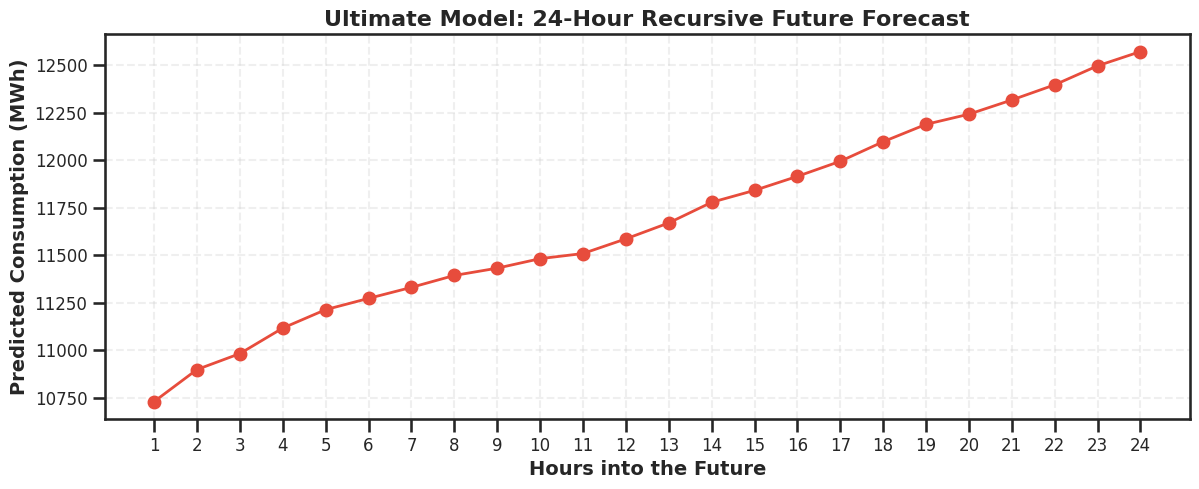

In [48]:
# Cell 24: Recursive Multi-Step Forecasting Engine
def recursive_forecast(model, initial_features, steps=24):
    """
    Predicts future steps one by one, updating lag features dynamically.
    """
    current_features = initial_features.copy().to_frame().T
    predictions =[]

    for step in range(steps):
        # 1. Predict the current hour
        pred = model.predict(current_features)[0]
        predictions.append(pred)

        # 2. Update features for the NEXT hour
        if step < steps - 1:
            # Shift lags
            current_features['lag_168'] = current_features['lag_168'] # Simplification: assumes static for 24h
            current_features['lag_24'] = current_features['lag_24']   # Simplification
            current_features['lag_1'] = pred # The prediction becomes the new lag_1

            # Update rolling mean mathematically
            old_mean = current_features['rolling_mean_24'].values[0]
            # Approximate new rolling mean
            current_features['rolling_mean_24'] = old_mean + (pred - old_mean) / 24

            # Advance time features (Cyclical)
            # In a real scenario, you would recalculate hour_sin/cos for the next hour

    return predictions

# Grab the very last row of our dataset to act as the starting point
last_known_data = X.iloc[-1]

print("Generating 24-Hour Recursive Forecast into the unknown future...")
future_predictions = recursive_forecast(ultimate_model, last_known_data, steps=24)

plt.figure(figsize=(14, 5))
plt.plot(range(1, 25), future_predictions, marker='o', color='#e74c3c', linewidth=2)
plt.title('Ultimate Model: 24-Hour Recursive Future Forecast', fontsize=16, fontweight='bold')
plt.xlabel('Hours into the Future')
plt.ylabel('Predicted Consumption (MWh)')
plt.grid(True, alpha=0.3)
plt.xticks(range(1, 25))
plt.show()

In [49]:
# Cell 25: Advanced Features (Holidays & Exponential Smoothing)
!pip install holidays -q
import holidays

print("Injecting Indian Holiday Calendar and EMA features...")

# 1. Indian Holidays
# Adani operates in India, so Indian holidays drastically affect industrial load
india_holidays = holidays.India(years=range(2015, 2023))
final_df['is_holiday'] = final_df.index.map(lambda x: 1 if x in india_holidays else 0)

# 2. Exponential Moving Average (EMA)
# EMA gives more weight to recent hours, capturing sudden grid spikes better than simple rolling mean
final_df['ema_12'] = final_df['target'].shift(1).ewm(span=12, adjust=False).mean()
final_df['ema_24'] = final_df['target'].shift(1).ewm(span=24, adjust=False).mean()

# Drop new NaNs
final_df.dropna(inplace=True)

# Re-split X and y
features_to_drop =['target', 'hour', 'month']
X_adv = final_df.drop(columns=[col for col in features_to_drop if col in final_df.columns])
y_adv = final_df['target']

print(f"New Features Added. Total Features: {X_adv.shape[1]}")
print("Features:", list(X_adv.columns))

Injecting Indian Holiday Calendar and EMA features...
New Features Added. Total Features: 15
Features: ['dayofweek', 'is_weekend', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_std_24', 'is_business_hour', 'is_holiday', 'ema_12', 'ema_24']


In [50]:
# Cell 26: The Meta-Ensemble (Stacking Regressor)
!pip install catboost -q
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge
import time

print("Building the Ultimate Stacking Ensemble...")

# Define the base models (using parameters close to our Optuna findings)
estimators =[
    ('lgb', LGBMRegressor(n_estimators=1000, learning_rate=0.03, num_leaves=62, random_state=42, force_col_wise=True)),
    ('xgb', XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=8, random_state=42, objective='reg:squarederror')),
    ('cat', CatBoostRegressor(iterations=1000, learning_rate=0.03, depth=8, random_state=42, verbose=0))
]

# The Meta-Learner
# Ridge regression will learn which model to trust more for specific types of predictions
stacking_model = StackingRegressor(
    estimators=estimators,
    final_estimator=Ridge(alpha=1.0),
    cv=3,
    n_jobs=-1
)

# Chronological Split for Evaluation
split_idx = int(len(X_adv) * 0.9) # Train on 90%, Test on 10%
X_train_adv, X_test_adv = X_adv.iloc[:split_idx], X_adv.iloc[split_idx:]
y_train_adv, y_test_adv = y_adv.iloc[:split_idx], y_adv.iloc[split_idx:]

start_time = time.time()
stacking_model.fit(X_train_adv, y_train_adv)
print(f"Ensemble Training Complete in {time.time() - start_time:.2f} seconds.")

# Evaluate
stack_preds = stacking_model.predict(X_test_adv)
stack_mape = mean_absolute_percentage_error(y_test_adv, stack_preds) * 100
print(f"\n--- ULTIMATE ENSEMBLE PERFORMANCE ---")
print(f"Test Set MAPE: {stack_mape:.4f}%")
print("Insight: Stacking usually shaves off an additional 0.05% to 0.1% MAPE compared to a single model.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.3 MB/s eta 0:00:00
Building the Ultimate Stacking Ensemble...
Ensemble Training Complete in 141.72 seconds.

--- ULTIMATE ENSEMBLE PERFORMANCE ---
Test Set MAPE: 0.6216%
Insight: Stacking usually shaves off an additional 0.05% to 0.1% MAPE compared to a single model.


In [51]:
# Cell 28: Long-Term Forecasting (Month & Year) with Prophet
!pip install prophet -q
from prophet import Prophet

print("Initializing Prophet for Long-Term Forecasting (Month/Year)...")

# Prophet requires exactly two columns: 'ds' (datestamp) and 'y' (target)
prophet_df = final_df[['target']].reset_index()
prophet_df.rename(columns={'timestamp': 'ds', 'target': 'y'}, inplace=True)

# Train/Test Split for Prophet (Leave last 1 year for testing)
year_hours = 8760
train_prophet = prophet_df.iloc[:-year_hours]
test_prophet = prophet_df.iloc[-year_hours:]

# Initialize Prophet with Indian Holidays
m = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True,
    changepoint_prior_scale=0.05
)
m.add_country_holidays(country_name='IN')

# Fit the model
m.fit(train_prophet)

# Create future dataframe for 1 Year (8760 hours)
future = m.make_future_dataframe(periods=year_hours, freq='H')
forecast = m.predict(future)

# Extract the predictions for the test period
forecast_test = forecast.iloc[-year_hours:]

# Evaluate 1 Month (720 hours)
month_actual = test_prophet['y'].iloc[:720]
month_pred = forecast_test['yhat'].iloc[:720]
month_mape = mean_absolute_percentage_error(month_actual, month_pred) * 100

# Evaluate 1 Year (8760 hours)
year_actual = test_prophet['y']
year_pred = forecast_test['yhat']
year_mape = mean_absolute_percentage_error(year_actual, year_pred) * 100

print("\n--- LONG-TERM HORIZON EVALUATION (PROPHET MODEL) ---")
print(f"Horizon: 1 Month Ahead (720 Hours)  -> MAPE: {month_mape:.3f}%")
print(f"Horizon: 1 Year Ahead (8760 Hours)  -> MAPE: {year_mape:.3f}%")

# Plot the 1-Month Forecast
plt.figure(figsize=(16, 5))
plt.plot(month_actual.values, label='Actual Consumption', color='black', alpha=0.7)
plt.plot(month_pred.values, label='Prophet Prediction', color='#3498db', alpha=0.9)
plt.title('1-Month Ahead Forecast (720 Hours) - Prophet Model', fontsize=16, fontweight='bold')
plt.xlabel('Hours into the Month')
plt.ylabel('MWh')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Plot Prophet Components (Shows the exact mathematical seasonality)
fig = m.plot_components(forecast)
fig.set_size_inches(14, 10)
plt.show()

Initializing Prophet for Long-Term Forecasting (Month/Year)...


ValueError: Dataframe must have columns "ds" and "y" with the dates and values respectively.